In [15]:
from pathlib import Path
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
TABLES_DIR = PROJECT_DIR / "results" / "tables"
FIGURES_DIR = PROJECT_DIR / "results" / "figures"

TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_DIR)

Project: c:\Users\ASUS\Documents\GitHub\Communication-Network-Failure-and-Resilience


In [16]:
edges = pd.read_csv(PROCESSED_DIR / "email_edges_clean.csv")
departments = pd.read_csv(
    PROCESSED_DIR / "email_departments_clean.csv"
)

for col in ["source", "target"]:
    edges[col] = pd.to_numeric(edges[col]).astype(int)

departments["node"] = pd.to_numeric(
    departments["node"]
).astype(int)

department_map = departments.set_index("node")[
    "department"
].to_dict()

G = nx.Graph()
G.add_edges_from(
    edges[["source", "target"]].itertuples(
        index=False, name=None
    )
)
G.add_nodes_from(departments["node"])

nx.set_node_attributes(G, department_map, "department")

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())
print(
    "Initial connected components:",
    nx.number_connected_components(G)
)

Number of nodes: 1005
Number of edges: 16706
Initial connected components: 20


In [17]:
print("Calculating node scores. This may take a little time...")

degree_scores = dict(G.degree())
betweenness_scores = nx.betweenness_centrality(
    G,
    normalized=True
)

bridge_rows = []

for node in G.nodes():
    own_department = department_map.get(node)
    neighbors = list(G.neighbors(node))

    known_neighbor_departments = [
        department_map.get(neighbor)
        for neighbor in neighbors
        if pd.notna(department_map.get(neighbor))
    ]

    cross_count = sum(
        1 for d in known_neighbor_departments
        if pd.notna(own_department) and d != own_department
    )

    known_count = len(known_neighbor_departments)

    cross_fraction = (
        cross_count / known_count
        if known_count else 0
    )

    bridge_rows.append({
        "node": node,
        "cross_department_neighbors": cross_count,
        "cross_department_fraction": cross_fraction,
        "betweenness_centrality": betweenness_scores[node]
    })

bridge_scores = pd.DataFrame(bridge_rows).set_index("node")

# Department-aware score:
# betweenness centrality weighted by cross-department fraction.
bridge_scores["department_aware_score"] = (
    bridge_scores["betweenness_centrality"]
    * bridge_scores["cross_department_fraction"]
)

degree_order = sorted(
    G.nodes(),
    key=lambda node: degree_scores[node],
    reverse=True
)

betweenness_order = sorted(
    G.nodes(),
    key=lambda node: betweenness_scores[node],
    reverse=True
)

department_aware_order = (
    bridge_scores["department_aware_score"]
    .sort_values(ascending=False)
    .index.tolist()
)

print("Node rankings created.")

Calculating node scores. This may take a little time...
Node rankings created.


### Resilience Measurement

We measure network resilience by removing **0%, 5%, 10%, 15%, ..., up to 50% of the nodes** and observing how the network changes after each removal.

At each removal level, we calculate the resilience using the following formula:

$$
R(p)=\frac{|\mathrm{LCC}(G_p)|}{|V|}
$$

Where:

- \(R(p)\) = Resilience value at removal proportion \(p\).
- \(p\) = Proportion of nodes removed from the original network.
- \(G_p\) = Remaining graph after removing a proportion \(p\) of nodes.
- \(\mathrm{LCC}(G_p)\) = Largest Connected Component of the remaining graph.
- \(|V|\) = Total number of nodes in the original network.

**Interpretation:**

- **Resilience close to 1:** Most of the original nodes remain connected within one large component, indicating high network resilience.
- **Resilience close to 0:** The network has become highly fragmented, indicating low network resilience.

By comparing resilience values across different node-removal levels, we can evaluate how effectively the network maintains its connectivity as nodes are removed.

Calculate node scores

In [18]:
REMOVAL_FRACTIONS = np.linspace(0, 0.50, 11)

def simulate_removal(graph, removal_order, fractions):
    original_n = graph.number_of_nodes()
    results = []

    for fraction in fractions:
        number_to_remove = int(round(fraction * original_n))

        removed = set(removal_order[:number_to_remove])
        remaining_nodes = [
            node for node in graph.nodes()
            if node not in removed
        ]

        remaining_graph = graph.subgraph(
            remaining_nodes
        )

        if remaining_graph.number_of_nodes() == 0:
            largest_component_size = 0
        else:
            largest_component_size = max(
                len(component)
                for component in nx.connected_components(
                    remaining_graph
                )
            )

        results.append({
            "removal_fraction": fraction,
            "removed_nodes": number_to_remove,
            "largest_component_size": largest_component_size,
            "largest_component_fraction": (
                largest_component_size / original_n
                if original_n else 0
            ),
            "remaining_nodes": len(remaining_nodes)
        })

    return pd.DataFrame(results)

**Create the simulation function**

In [19]:
REMOVAL_FRACTIONS = np.linspace(0, 0.50, 11)

def simulate_removal(graph, removal_order, fractions):
    original_n = graph.number_of_nodes()
    results = []

    for fraction in fractions:
        number_to_remove = int(round(fraction * original_n))

        removed = set(removal_order[:number_to_remove])
        remaining_nodes = [
            node for node in graph.nodes()
            if node not in removed
        ]

        remaining_graph = graph.subgraph(
            remaining_nodes
        )

        if remaining_graph.number_of_nodes() == 0:
            largest_component_size = 0
        else:
            largest_component_size = max(
                len(component)
                for component in nx.connected_components(
                    remaining_graph
                )
            )

        results.append({
            "removal_fraction": fraction,
            "removed_nodes": number_to_remove,
            "largest_component_size": largest_component_size,
            "largest_component_fraction": (
                largest_component_size / original_n
                if original_n else 0
            ),
            "remaining_nodes": len(remaining_nodes)
        })

    return pd.DataFrame(results)

In [20]:
print("Running degree-based simulation...")
degree_result = simulate_removal(
    G, degree_order, REMOVAL_FRACTIONS
)
degree_result["strategy"] = "Degree-based"

print("Running betweenness-based simulation...")
betweenness_result = simulate_removal(
    G, betweenness_order, REMOVAL_FRACTIONS
)
betweenness_result["strategy"] = "Betweenness-based"

print("Running department-aware simulation...")
department_result = simulate_removal(
    G, department_aware_order, REMOVAL_FRACTIONS
)
department_result["strategy"] = "Department-aware"

print("Targeted simulations completed.")

Running degree-based simulation...
Running betweenness-based simulation...
Running department-aware simulation...
Targeted simulations completed.


**Random removal baseline**

In [21]:
N_RANDOM_RUNS = 20
random_results = []

nodes = list(G.nodes())

for run in range(N_RANDOM_RUNS):
    rng = np.random.default_rng(42 + run)
    random_order = rng.permutation(nodes).tolist()

    one_run = simulate_removal(
        G, random_order, REMOVAL_FRACTIONS
    )

    one_run["run"] = run + 1
    random_results.append(one_run)

random_all = pd.concat(
    random_results,
    ignore_index=True
)

random_result = (
    random_all.groupby("removal_fraction", as_index=False)
    .agg(
        removed_nodes=("removed_nodes", "mean"),
        largest_component_size=("largest_component_size", "mean"),
        largest_component_fraction=(
            "largest_component_fraction", "mean"
        ),
        remaining_nodes=("remaining_nodes", "mean")
    )
)

random_result["strategy"] = "Random (20-run average)"

print("Random simulations completed.")
display(random_result)

Random simulations completed.


,removal_fraction,removed_nodes,largest_component_size,largest_component_fraction,remaining_nodes,strategy
0,0.00,0.0,986.00,0.981095,1005.0,Random (20-run average)
1,0.05,50.0,932.25,0.927612,955.0,Random (20-run average)
2,0.10,100.0,879.15,0.874776,905.0,Random (20-run average)
3,0.15,151.0,824.25,0.820149,854.0,Random (20-run average)
4,0.20,201.0,772.80,0.768955,804.0,Random (20-run average)
5,0.25,251.0,720.40,0.716816,754.0,Random (20-run average)
6,0.30,302.0,666.80,0.663483,703.0,Random (20-run average)
7,0.35,352.0,614.65,0.611592,653.0,Random (20-run average)
8,0.40,402.0,564.00,0.561194,603.0,Random (20-run average)
9,0.45,452.0,513.05,0.510498,553.0,Random (20-run average)


In [22]:
results = pd.concat(
    [
        random_result,
        degree_result,
        betweenness_result,
        department_result
    ],
    ignore_index=True
)

results = results.sort_values(
    ["strategy", "removal_fraction"]
).reset_index(drop=True)

display(results.head(15))

output_path = TABLES_DIR / "network_resilience_comparison.csv"
results.to_csv(output_path, index=False)

print("Saved:", output_path)

,removal_fraction,removed_nodes,largest_component_size,largest_component_fraction,remaining_nodes,strategy
0,0.00,0.0,986.0,0.981095,1005.0,Betweenness-based
1,0.05,50.0,896.0,0.891542,955.0,Betweenness-based
2,0.10,100.0,812.0,0.807960,905.0,Betweenness-based
3,0.15,151.0,726.0,0.722388,854.0,Betweenness-based
4,0.20,201.0,638.0,0.634826,804.0,Betweenness-based
5,0.25,251.0,569.0,0.566169,754.0,Betweenness-based
6,0.30,302.0,501.0,0.498507,703.0,Betweenness-based
7,0.35,352.0,424.0,0.421891,653.0,Betweenness-based
8,0.40,402.0,336.0,0.334328,603.0,Betweenness-based
9,0.45,452.0,248.0,0.246766,553.0,Betweenness-based


Saved: c:\Users\ASUS\Documents\GitHub\Communication-Network-Failure-and-Resilience\results\tables\network_resilience_comparison.csv


**Plot the resilience curves**

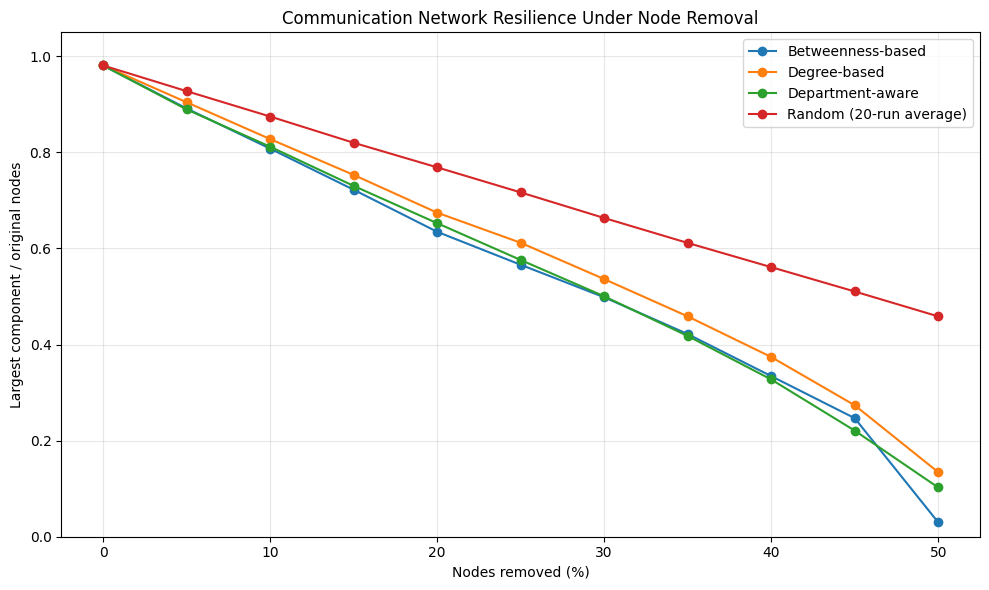

Saved: c:\Users\ASUS\Documents\GitHub\Communication-Network-Failure-and-Resilience\results\figures\network_resilience_comparison.png


In [24]:
plt.figure(figsize=(10, 6))

for strategy, group in results.groupby("strategy"):
    group = group.sort_values("removal_fraction")

    plt.plot(
        group["removal_fraction"] * 100,
        group["largest_component_fraction"],
        marker="o",
        label=strategy
    )

plt.title("Communication Network Resilience Under Node Removal")
plt.xlabel("Nodes removed (%)")
plt.ylabel("Largest component / original nodes")
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

figure_path = FIGURES_DIR / "network_resilience_comparison.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", figure_path)

In [25]:
auc_rows = []

for strategy, group in results.groupby("strategy"):
    group = group.sort_values("removal_fraction")

    auc = np.trapezoid(
        group["largest_component_fraction"],
        group["removal_fraction"]
    )

    auc_rows.append({
        "strategy": strategy,
        "resilience_auc_0_to_50_percent": auc,
        "interpretation": (
            "Higher AUC indicates greater retained connectivity"
        )
    })

auc_df = pd.DataFrame(auc_rows).sort_values(
    "resilience_auc_0_to_50_percent",
    ascending=False
)

display(auc_df)

auc_df.to_csv(
    TABLES_DIR / "resilience_auc_comparison.csv",
    index=False
)

print("Saved resilience_auc_comparison.csv")

,strategy,resilience_auc_0_to_50_percent,interpretation
3,Random (20-run average),0.358748,Higher AUC indicates greater retained connecti...
1,Degree-based,0.298632,Higher AUC indicates greater retained connecti...
2,Department-aware,0.283458,Higher AUC indicates greater retained connecti...
0,Betweenness-based,0.281493,Higher AUC indicates greater retained connecti...


Saved resilience_auc_comparison.csv
